# ECG Arrhythmia Classification Using PyTorch LSTM and GRU

## Overview

This notebook investigates recurrent neural network architectures for ECG heartbeat classification.

Unlike convolutional networks, recurrent neural networks process sequential information by maintaining internal hidden states.

Two recurrent architectures are implemented:

- Long Short-Term Memory (LSTM).
- Gated Recurrent Unit (GRU).

Both architectures are evaluated using standard CrossEntropyLoss and class-weighted CrossEntropyLoss.

The experiments aim to compare their ability to learn temporal representations from ECG signals and investigate the effect of class weighting.


## 1. Objectives

1. Prepare ECG signals for recurrent neural network processing.
2. Reuse the common Dataset and DataLoader implementation.
3. Implement LSTM and GRU architectures in PyTorch.
4. Train both architectures using standard CrossEntropyLoss.
5. Train both architectures using class-weighted CrossEntropyLoss.
6. Apply early stopping and save the best checkpoints.
7. Evaluate all four experiments using validation metrics.
8. Compare LSTM and GRU performance.
9. Analyze the impact of class weighting on recurrent architectures.


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
print(torch.__version__)

2.11.0+cu128


# INITIAL SETUP

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [3]:
torch.manual_seed(0)

In [4]:
!nvidia-smi

Sun Nov 22 01:43:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 591.66                 Driver Version: 591.66         CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 4050 ...  WDDM  |   00000000:01:00.0  On |                  N/A |
| N/A   41C    P5              3W /   44W |    1637MiB /   6141MiB |      9%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----


## 2. Dataset Preparation

The same training and validation split used in the CNN experiments is reused.

Each ECG heartbeat contains 187 sequential numerical values.

For recurrent networks, each signal is reshaped into:

`(batch_size, sequence_length, input_size)`

The input shape becomes:

`(batch_size, 187, 1)`

Here:

- Batch size represents the number of ECG samples processed together.
- Sequence length represents the 187 signal positions.
- Input size represents one feature at each timestep.

The same Dataset and DataLoader implementation is used for both LSTM and GRU experiments.


In [5]:
train_df = pd.read_csv("../data/raw/mitbih_train.csv")
train_idx = np.load("../data/processed/train_idx.npy")
val_idx = np.load("../data/processed/val_idx.npy")

train_df.head()

,9.779411554336547852e-01,9.264705777168273926e-01,6.813725233078002930e-01,2.450980395078659058e-01,1.544117629528045654e-01,1.911764740943908691e-01,1.519607901573181152e-01,8.578431606292724609e-02,5.882352963089942932e-02,4.901960864663124084e-02,...,0.000000000000000000e+00.79,0.000000000000000000e+00.80,0.000000000000000000e+00.81,0.000000000000000000e+00.82,0.000000000000000000e+00.83,0.000000000000000000e+00.84,0.000000000000000000e+00.85,0.000000000000000000e+00.86,0.000000000000000000e+00.87,0.000000000000000000e+00.88
0,0.960114,0.863248,0.461538,0.196581,0.094017,0.125356,0.099715,0.088319,0.074074,0.082621,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.659459,0.186486,0.070270,0.070270,0.059459,0.056757,0.043243,0.054054,0.045946,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.925414,0.665746,0.541436,0.276243,0.196133,0.077348,0.071823,0.060773,0.066298,0.058011,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.967136,1.000000,0.830986,0.586854,0.356808,0.248826,0.145540,0.089202,0.117371,0.150235,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.927461,1.000000,0.626943,0.193437,0.094991,0.072539,0.043178,0.053541,0.093264,0.189983,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
X = train_df.iloc[:,:-1]
y = train_df.iloc[:,-1]

In [7]:
train_X = X.iloc[train_idx]
val_X = X.iloc[val_idx]

train_y = y.iloc[train_idx]
val_y = y.iloc[val_idx]

In [8]:
print("Training shape:", train_X.shape)
print("Validation shape:", val_X.shape)

print("\nTraining class distribution:")
print(train_y.value_counts().sort_index())

print("\nValidation class distribution:")
print(val_y.value_counts().sort_index())

Training shape: (74420, 187)
Validation shape: (13133, 187)

Training class distribution:
0.000000000000000000e+00.88
0.0    61599
1.0     1890
2.0     4920
3.0      545
4.0     5466
Name: count, dtype: int64

Validation class distribution:
0.000000000000000000e+00.88
0.0    10871
1.0      333
2.0      868
3.0       96
4.0      965
Name: count, dtype: int64


In [9]:
train_features = train_X
train_labels = train_y

val_features = val_X
val_labels = val_y

In [10]:
train_features = torch.tensor(train_features.to_numpy(), dtype=torch.float32)
train_labels = torch.tensor(train_labels.to_numpy(), dtype=torch.long)

val_features = torch.tensor(val_features.to_numpy(), dtype=torch.float32)
val_labels = torch.tensor(val_labels.to_numpy(), dtype=torch.long)

In [11]:
class ECGDataset(Dataset):
    def __init__(self, features, labels):
        self.features = features
        self.labels = labels

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        signal = self.features[idx]
        label = self.labels[idx]

        return signal, label

In [12]:
train_dataset = ECGDataset(train_features, train_labels)
val_dataset = ECGDataset(val_features, val_labels)

In [13]:
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))

print("Signal shape:", train_dataset[0][0].shape)
print("Label:", train_dataset[0][1])

Training: 74420
Validation: 13133
Signal shape: torch.Size([187])
Label: tensor(0)


In [14]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True,pin_memory=True)
val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False,pin_memory=True)


## 3. Recurrent Neural Network Architecture

A reusable ECG_RNN class is implemented to support both LSTM and GRU cells.

The recurrent cell is selected through a configuration parameter, allowing the same architecture implementation to be reused.

### Architecture Configuration

- Input size: 1.
- Hidden size: 64.
- Number of recurrent layers: 2.
- Dropout: 0.2.
- Bidirectional processing: Enabled.
- Number of output classes: 5.

### Bidirectional Processing

The recurrent network processes the input sequence in both forward and backward directions.

This allows the representation at each timestep to incorporate information from both directions of the ECG sequence.

### Feature Aggregation

The recurrent output is aggregated using two operations:

1. Mean pooling across the sequence dimension.
2. Max pooling across the sequence dimension.

Both representations are concatenated to form a 256-dimensional feature vector.

A dropout layer and linear classification layer then generate five output logits.

In [15]:
class ECG_RNN(nn.Module):
    def __init__(self, cell="lstm", hidden=64, layers=2, dropout=0.2, n_classes=5):
        super().__init__()
        rnn = nn.LSTM if cell == "lstm" else nn.GRU
        self.rnn = rnn(input_size=1, hidden_size=hidden, num_layers=layers,
                       batch_first=True, dropout=dropout, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden * 4, n_classes))

    def forward(self, x):                      # x: (B, 187)
        x = x.unsqueeze(-1)                    # (B, 187, 1)
        out, _ = self.rnn(x)                   # (B, 187, 2*hidden)
        feat = torch.cat([out.mean(dim=1), out.max(dim=1).values], dim=1)
        return self.head(feat)

In [16]:
classes = np.unique(train_y)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_y
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print(class_weights)

tensor([ 0.2416,  7.8751,  3.0252, 27.3101,  2.7230], device='cuda:0')



## 4. Experiment 1 - LSTM with Standard CrossEntropyLoss

The first experiment uses an LSTM recurrent cell with the standard CrossEntropyLoss function.

The LSTM uses memory cells and gating mechanisms to learn sequential dependencies.

The model is trained using the shared training configuration, and its best checkpoint is selected using validation Macro-F1.

Training history, classification report and confusion matrix are saved.

In [17]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0

lstm_plain_model = ECG_RNN(cell='lstm').to(device)
criterion_lstm_plain = nn.CrossEntropyLoss()
optimizer_lstm_plain = optim.Adam(lstm_plain_model.parameters(), lr=learning_rate)

history_plain_lstm = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    lstm_plain_model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_lstm_plain.zero_grad()

        outputs = lstm_plain_model(features)

        loss = criterion_lstm_plain(outputs, labels)

        loss.backward()

        optimizer_lstm_plain.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    lstm_plain_model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = lstm_plain_model(features)

            loss = criterion_lstm_plain(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_plain_lstm["epoch"].append(epoch + 1)
    history_plain_lstm["train_loss"].append(avg_train_loss)
    history_plain_lstm["val_loss"].append(avg_val_loss)
    history_plain_lstm["accuracy"].append(accuracy)
    history_plain_lstm["balanced_accuracy"].append(balanced_acc)
    history_plain_lstm["precision"].append(precision)
    history_plain_lstm["recall"].append(recall)
    history_plain_lstm["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            lstm_plain_model.state_dict(),
            "../models/lstm_plain.pt"
        )

        print("Best LSTM PLAIN model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best LSTM PLAIN model saved!
Epoch [1/50] Train Loss: 0.3954 | Val Loss: 0.2365 | Accuracy: 0.9391 | Balanced Acc: 0.5333 | Macro F1: 0.5717
Best LSTM PLAIN model saved!
Epoch [2/50] Train Loss: 0.2202 | Val Loss: 0.1888 | Accuracy: 0.9466 | Balanced Acc: 0.5859 | Macro F1: 0.6373
Best LSTM PLAIN model saved!
Epoch [3/50] Train Loss: 0.1741 | Val Loss: 0.1357 | Accuracy: 0.9627 | Balanced Acc: 0.7877 | Macro F1: 0.8208
Best LSTM PLAIN model saved!
Epoch [4/50] Train Loss: 0.1498 | Val Loss: 0.1139 | Accuracy: 0.9685 | Balanced Acc: 0.7724 | Macro F1: 0.8255
Best LSTM PLAIN model saved!
Epoch [5/50] Train Loss: 0.1325 | Val Loss: 0.1018 | Accuracy: 0.9713 | Balanced Acc: 0.8149 | Macro F1: 0.8536
Epoch [6/50] Train Loss: 0.1175 | Val Loss: 0.0979 | Accuracy: 0.9714 | Balanced Acc: 0.7972 | Macro F1: 0.8485
Best LSTM PLAIN model saved!
Epoch [7/50] Train Loss: 0.1072 | Val Loss: 0.0923 | Accuracy: 0.9740 | Balanced Acc: 0.8280 | Macro F1: 0.8630
Best LSTM PLAIN model saved!
Epoch [8/50] 

In [18]:
history_plain_lstm_df = pd.DataFrame(history_plain_lstm)

history_plain_lstm_df.to_csv(
    "../results/metrics/lstm_plain_history.csv",
    index=False
)

In [19]:
lstm_plain_model.load_state_dict(
    torch.load(
        "../models/lstm_plain.pt",
        map_location=device,
        weights_only=True
    )
)

lstm_plain_model.eval()

print("Best LSTM PLAIN model loaded successfully!")

Best LSTM PLAIN model loaded successfully!


In [20]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = lstm_plain_model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [21]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/lstm_plain_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.992764,0.997056,0.994906,10871.000000
Supraventricular,0.945392,0.831832,0.884984,333.000000
Ventricular,0.970218,0.975806,0.973004,868.000000
Fusion,0.919540,0.833333,0.874317,96.000000
Unknown,0.995842,0.992746,0.994292,965.000000
accuracy,0.989949,0.989949,0.989949,0.989949
macro avg,0.964751,0.926155,0.944300,13133.000000
weighted avg,0.989764,0.989949,0.989744,13133.000000


In [22]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/lstm_plain_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10839,15,12,1,4
Supraventricular,53,277,3,0,0
Ventricular,14,1,847,6,0
Fusion,6,0,10,80,0
Unknown,6,0,1,0,958


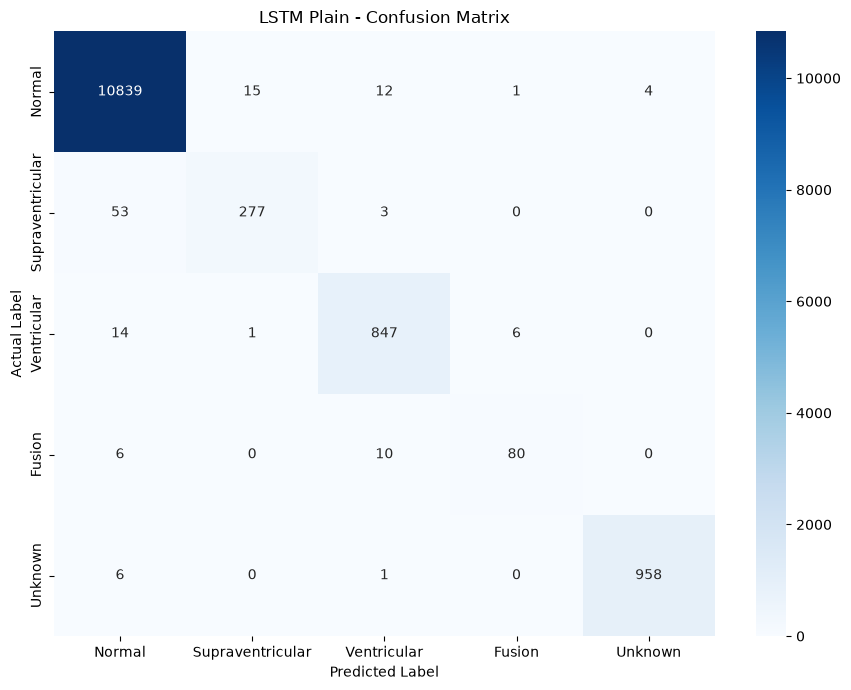

In [23]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Plain - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_plain_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

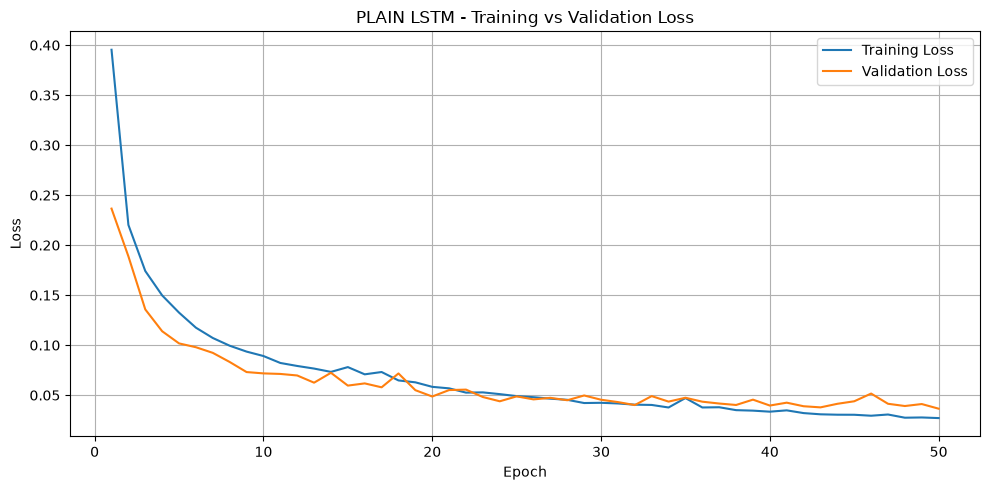

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_plain_lstm_df["epoch"],
    history_plain_lstm_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_plain_lstm_df["epoch"],
    history_plain_lstm_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PLAIN LSTM - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_plain_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

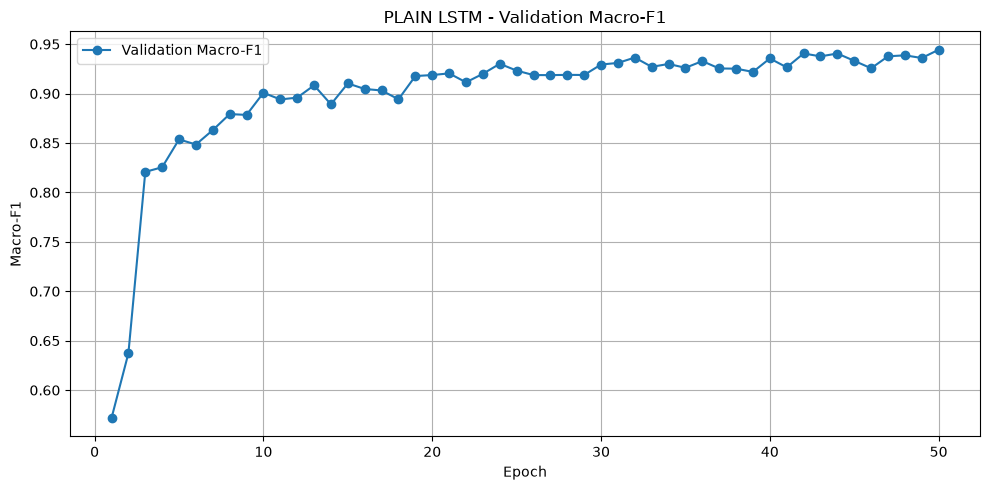

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_plain_lstm_df["epoch"],
    history_plain_lstm_df["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("PLAIN LSTM - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_plain_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 5. Experiment 2 - Weighted LSTM

The second LSTM experiment introduces class weights calculated using the balanced class-weight strategy.

The weighted loss increases the contribution of errors involving underrepresented classes.

A new LSTM model and optimizer are initialized before training.

The objective is to investigate whether weighted loss improves the recognition of minority heartbeat categories.


In [26]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0

lstm_weighted_model = ECG_RNN(cell='lstm').to(device)
criterion_lstm_weighted = nn.CrossEntropyLoss(weight=class_weights)
optimizer_lstm_weighted = optim.Adam(lstm_weighted_model.parameters(), lr=learning_rate)

history_weighted_lstm = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    lstm_weighted_model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_lstm_weighted.zero_grad()

        outputs = lstm_weighted_model(features)

        loss = criterion_lstm_weighted(outputs, labels)

        loss.backward()

        optimizer_lstm_weighted.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    lstm_weighted_model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = lstm_weighted_model(features)

            loss = criterion_lstm_weighted(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_weighted_lstm["epoch"].append(epoch + 1)
    history_weighted_lstm["train_loss"].append(avg_train_loss)
    history_weighted_lstm["val_loss"].append(avg_val_loss)
    history_weighted_lstm["accuracy"].append(accuracy)
    history_weighted_lstm["balanced_accuracy"].append(balanced_acc)
    history_weighted_lstm["precision"].append(precision)
    history_weighted_lstm["recall"].append(recall)
    history_weighted_lstm["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            lstm_weighted_model.state_dict(),
            "../models/lstm_weighted.pt"
        )

        print("Best WEIGHTED LSTM model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best WEIGHTED LSTM model saved!
Epoch [1/50] Train Loss: 1.4749 | Val Loss: 1.3567 | Accuracy: 0.6346 | Balanced Acc: 0.3270 | Macro F1: 0.2844
Best WEIGHTED LSTM model saved!
Epoch [2/50] Train Loss: 1.4845 | Val Loss: 1.5281 | Accuracy: 0.7664 | Balanced Acc: 0.3086 | Macro F1: 0.3041
Best WEIGHTED LSTM model saved!
Epoch [3/50] Train Loss: 0.9210 | Val Loss: 0.5781 | Accuracy: 0.7873 | Balanced Acc: 0.8058 | Macro F1: 0.5672
Best WEIGHTED LSTM model saved!
Epoch [4/50] Train Loss: 0.6404 | Val Loss: 0.7336 | Accuracy: 0.8370 | Balanced Acc: 0.6946 | Macro F1: 0.5760
Best WEIGHTED LSTM model saved!
Epoch [5/50] Train Loss: 0.6093 | Val Loss: 0.6007 | Accuracy: 0.7552 | Balanced Acc: 0.7820 | Macro F1: 0.5956
Best WEIGHTED LSTM model saved!
Epoch [6/50] Train Loss: 0.4836 | Val Loss: 0.4215 | Accuracy: 0.8458 | Balanced Acc: 0.8423 | Macro F1: 0.6371
Epoch [7/50] Train Loss: 0.4376 | Val Loss: 0.3960 | Accuracy: 0.7889 | Balanced Acc: 0.8601 | Macro F1: 0.5993
Best WEIGHTED LSTM model

In [27]:
history_lstm_weighted_df = pd.DataFrame(history_weighted_lstm)

history_lstm_weighted_df.to_csv(
    "../results/metrics/lstm_weighted_history.csv",
    index=False
)

In [28]:
lstm_weighted_model.load_state_dict(
    torch.load(
        "../models/lstm_weighted.pt",
        map_location=device,
        weights_only=True
    )
)

lstm_weighted_model.eval()

print("Best LSTM WEIGHTED model loaded successfully!")

Best LSTM WEIGHTED model loaded successfully!


In [29]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = lstm_weighted_model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [30]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/lstm_weighted_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.993163,0.975439,0.984221,10871.000000
Supraventricular,0.656325,0.825826,0.731383,333.000000
Ventricular,0.904348,0.958525,0.930649,868.000000
Fusion,0.582192,0.885417,0.702479,96.000000
Unknown,0.978373,0.984456,0.981405,965.000000
accuracy,0.970532,0.970532,0.970532,0.970532
macro avg,0.822880,0.925933,0.866027,13133.000000
weighted avg,0.974661,0.970532,0.972003,13133.000000


In [31]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/lstm_weighted_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10604,143,71,36,17
Supraventricular,49,275,5,1,3
Ventricular,11,0,832,24,1
Fusion,5,1,5,85,0
Unknown,8,0,7,0,950


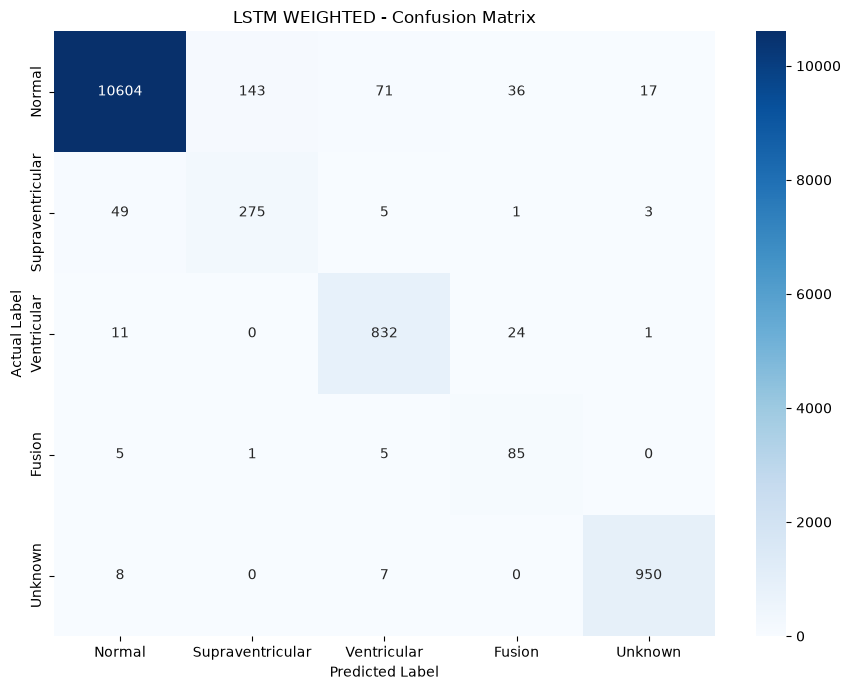

In [32]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM WEIGHTED - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_weighted_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

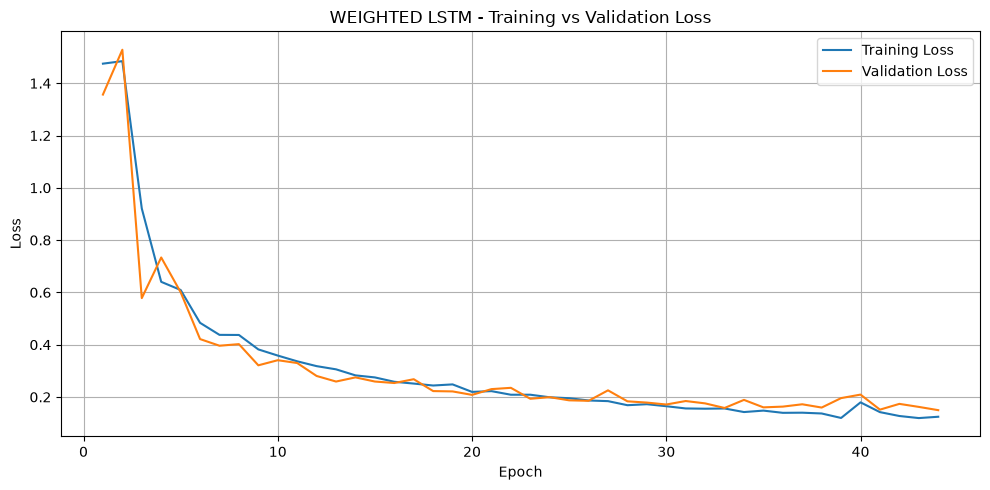

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm_weighted_df["epoch"],
    history_lstm_weighted_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_lstm_weighted_df["epoch"],
    history_lstm_weighted_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("WEIGHTED LSTM - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_weighted_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

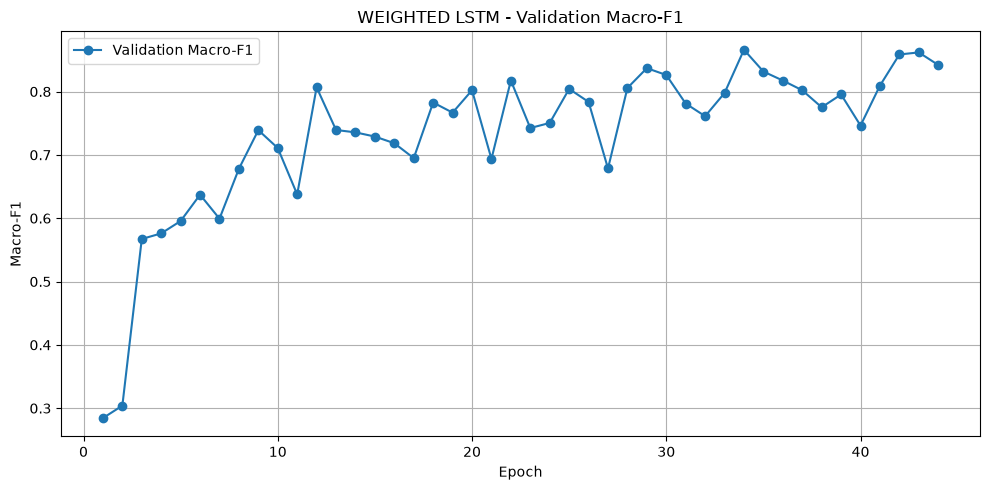

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_weighted_lstm["epoch"],
    history_weighted_lstm["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("WEIGHTED LSTM - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/lstm_weighted_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Experiment 3 - GRU with Standard CrossEntropyLoss

The third experiment replaces the LSTM cell with a GRU cell while maintaining the same overall architecture configuration.

GRU uses update and reset gates to control information flow through the recurrent network.

Compared with LSTM, GRU has a simpler internal gating structure.

The same training and validation setup is maintained to ensure a fair comparison.


In [35]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0

gru_plain_model = ECG_RNN(cell='gru').to(device)
criterion_gru_plain = nn.CrossEntropyLoss()
optimizer_gru_plain = optim.Adam(gru_plain_model.parameters(), lr=learning_rate)

history_gru_plain = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    gru_plain_model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_gru_plain.zero_grad()

        outputs = gru_plain_model(features)

        loss = criterion_gru_plain(outputs, labels)

        loss.backward()

        optimizer_gru_plain.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    gru_plain_model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = gru_plain_model(features)

            loss = criterion_gru_plain(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_gru_plain["epoch"].append(epoch + 1)
    history_gru_plain["train_loss"].append(avg_train_loss)
    history_gru_plain["val_loss"].append(avg_val_loss)
    history_gru_plain["accuracy"].append(accuracy)
    history_gru_plain["balanced_accuracy"].append(balanced_acc)
    history_gru_plain["precision"].append(precision)
    history_gru_plain["recall"].append(recall)
    history_gru_plain["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            gru_plain_model.state_dict(),
            "../models/gru_plain.pt"
        )

        print("Best GRU PLAIN model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best GRU PLAIN model saved!
Epoch [1/50] Train Loss: 0.3187 | Val Loss: 0.1646 | Accuracy: 0.9520 | Balanced Acc: 0.6488 | Macro F1: 0.7165
Best GRU PLAIN model saved!
Epoch [2/50] Train Loss: 0.1563 | Val Loss: 0.1219 | Accuracy: 0.9670 | Balanced Acc: 0.8007 | Macro F1: 0.8335
Best GRU PLAIN model saved!
Epoch [3/50] Train Loss: 0.1238 | Val Loss: 0.1032 | Accuracy: 0.9704 | Balanced Acc: 0.8360 | Macro F1: 0.8402
Best GRU PLAIN model saved!
Epoch [4/50] Train Loss: 0.1068 | Val Loss: 0.0764 | Accuracy: 0.9797 | Balanced Acc: 0.8634 | Macro F1: 0.8918
Epoch [5/50] Train Loss: 0.0956 | Val Loss: 0.0841 | Accuracy: 0.9763 | Balanced Acc: 0.8627 | Macro F1: 0.8712
Epoch [6/50] Train Loss: 0.0874 | Val Loss: 0.0778 | Accuracy: 0.9791 | Balanced Acc: 0.8878 | Macro F1: 0.8908
Best GRU PLAIN model saved!
Epoch [7/50] Train Loss: 0.0809 | Val Loss: 0.0623 | Accuracy: 0.9827 | Balanced Acc: 0.8828 | Macro F1: 0.9090
Best GRU PLAIN model saved!
Epoch [8/50] Train Loss: 0.0742 | Val Loss: 0.05

In [36]:
history_gru_plain_df = pd.DataFrame(history_gru_plain)

history_gru_plain_df.to_csv(
    "../results/metrics/gru_plain_history.csv",
    index=False
)

In [37]:
gru_plain_model.load_state_dict(
    torch.load(
        "../models/gru_plain.pt",
        map_location=device,
        weights_only=True
    )
)

gru_plain_model.eval()

print("Best PLAIN GRU model loaded successfully!")

Best PLAIN GRU model loaded successfully!


In [38]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = gru_plain_model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [39]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/gru_plain_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.994123,0.995769,0.994945,10871.000000
Supraventricular,0.935897,0.876877,0.905426,333.000000
Ventricular,0.974742,0.978111,0.976423,868.000000
Fusion,0.877778,0.822917,0.849462,96.000000
Unknown,0.987642,0.993782,0.990702,965.000000
accuracy,0.990177,0.990177,0.990177,0.990177
macro avg,0.954036,0.933491,0.943392,13133.000000
weighted avg,0.990039,0.990177,0.990076,13133.000000


In [40]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/gru_plain_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10825,19,11,5,11
Supraventricular,40,292,1,0,0
Ventricular,12,0,849,6,1
Fusion,7,1,9,79,0
Unknown,5,0,1,0,959


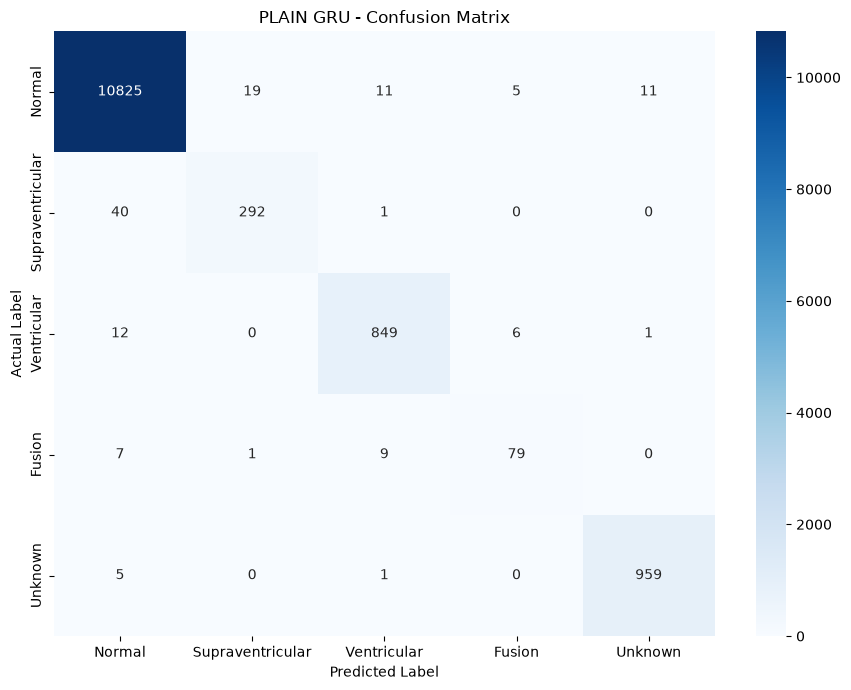

In [41]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("PLAIN GRU - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/gru_plain_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

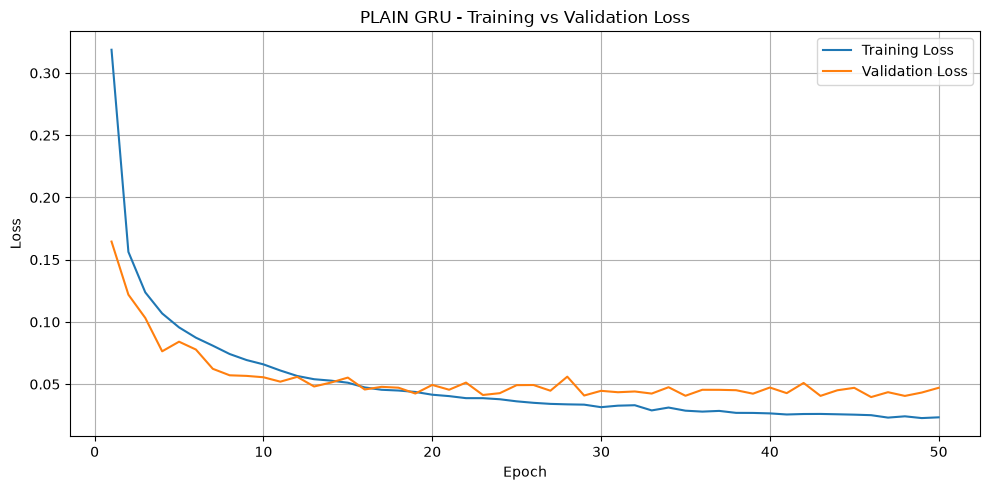

In [42]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gru_plain["epoch"],
    history_gru_plain["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_gru_plain["epoch"],
    history_gru_plain["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PLAIN GRU - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/gru_plain_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

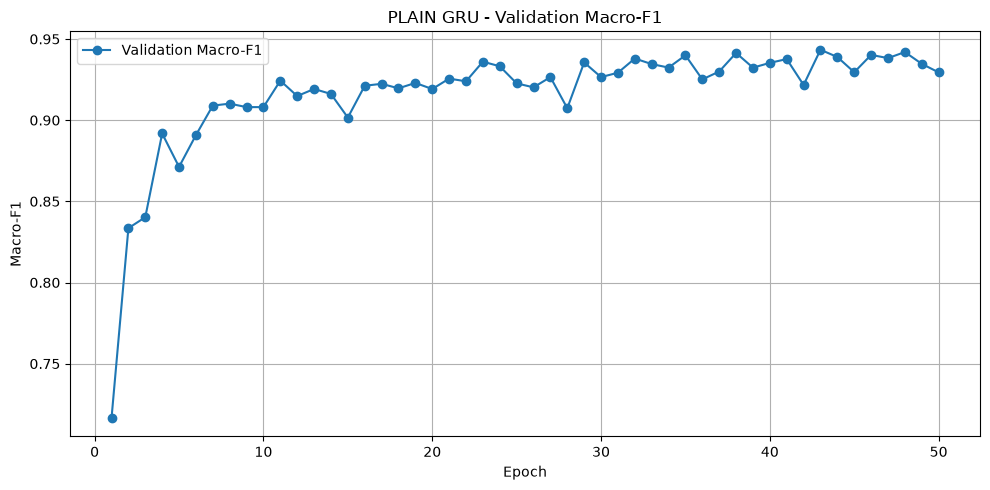

In [43]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gru_plain["epoch"],
    history_gru_plain["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("PLAIN GRU - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/plain_gru_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Experiment 4 - Weighted GRU

The fourth experiment trains the GRU architecture using class-weighted CrossEntropyLoss.

The same class-weight calculation strategy is used as in the other weighted experiments.

A fresh GRU model and optimizer are initialized.

This experiment allows the impact of class weighting to be compared across both recurrent architectures.


In [44]:
learning_rate = 0.001
epochs = 50
patience = 10
patience_counter = 0
best_macro_f1 = 0

gru_weighted_model = ECG_RNN(cell='gru').to(device)
criterion_gru_weighted = nn.CrossEntropyLoss(weight=class_weights)
optimizer_gru_weighted = optim.Adam(gru_weighted_model.parameters(), lr=learning_rate)

history_gru_weighted = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "balanced_accuracy": [],
    "precision": [],
    "recall": [],
    "macro_f1": []
}


for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    gru_weighted_model.train()

    total_train_loss = 0
    train_samples = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device)

        optimizer_gru_weighted.zero_grad()

        outputs = gru_weighted_model(features)

        loss = criterion_gru_weighted(outputs, labels)

        loss.backward()

        optimizer_gru_weighted.step()

        total_train_loss += loss.item() * features.size(0)
        train_samples += features.size(0)

    avg_train_loss = total_train_loss / train_samples

    # ---------------- VALIDATION ----------------
    gru_weighted_model.eval()

    total_val_loss = 0
    val_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = gru_weighted_model(features)

            loss = criterion_gru_weighted(outputs, labels)

            total_val_loss += loss.item() * features.size(0)
            val_samples += features.size(0)

            predictions = torch.argmax(outputs, dim=1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_val_loss = total_val_loss / val_samples

    # ---------------- METRICS ----------------
    accuracy = accuracy_score(all_labels, all_preds)

    balanced_acc = balanced_accuracy_score(
        all_labels, all_preds
    )

    precision = precision_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    recall = recall_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    macro_f1 = f1_score(
        all_labels, all_preds,
        average="macro", zero_division=0
    )

    # ---------------- SAVE HISTORY ----------------
    history_gru_weighted["epoch"].append(epoch + 1)
    history_gru_weighted["train_loss"].append(avg_train_loss)
    history_gru_weighted["val_loss"].append(avg_val_loss)
    history_gru_weighted["accuracy"].append(accuracy)
    history_gru_weighted["balanced_accuracy"].append(balanced_acc)
    history_gru_weighted["precision"].append(precision)
    history_gru_weighted["recall"].append(recall)
    history_gru_weighted["macro_f1"].append(macro_f1)

    # ---------------- EARLY STOPPING ----------------
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1
        best_epoch = epoch + 1
        patience_counter = 0

        torch.save(
            gru_weighted_model.state_dict(),
            "../models/gru_weighted.pt"
        )

        print("Best GRU WEIGHTED model saved!")

    else:

        patience_counter += 1

    # ---------------- EPOCH RESULTS ----------------
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Balanced Acc: {balanced_acc:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

    if patience_counter >= patience:

        print("Early stopping triggered!")
        break

Best GRU WEIGHTED model saved!
Epoch [1/50] Train Loss: 0.9454 | Val Loss: 0.5855 | Accuracy: 0.7349 | Balanced Acc: 0.8037 | Macro F1: 0.5583
Epoch [2/50] Train Loss: 0.5161 | Val Loss: 0.4641 | Accuracy: 0.6931 | Balanced Acc: 0.8299 | Macro F1: 0.5481
Best GRU WEIGHTED model saved!
Epoch [3/50] Train Loss: 0.4252 | Val Loss: 0.3527 | Accuracy: 0.8511 | Balanced Acc: 0.8655 | Macro F1: 0.6733
Epoch [4/50] Train Loss: 0.3720 | Val Loss: 0.3498 | Accuracy: 0.8712 | Balanced Acc: 0.8631 | Macro F1: 0.6637
Best GRU WEIGHTED model saved!
Epoch [5/50] Train Loss: 0.3329 | Val Loss: 0.2764 | Accuracy: 0.9188 | Balanced Acc: 0.8999 | Macro F1: 0.7618
Epoch [6/50] Train Loss: 0.3036 | Val Loss: 0.2594 | Accuracy: 0.9022 | Balanced Acc: 0.9012 | Macro F1: 0.7075
Epoch [7/50] Train Loss: 0.2815 | Val Loss: 0.2581 | Accuracy: 0.8253 | Balanced Acc: 0.8949 | Macro F1: 0.6888
Epoch [8/50] Train Loss: 0.2586 | Val Loss: 0.2110 | Accuracy: 0.8610 | Balanced Acc: 0.9163 | Macro F1: 0.7418
Best GRU WE

In [45]:
history_gru_weighted_df = pd.DataFrame(history_gru_weighted)

history_gru_weighted_df.to_csv(
    "../results/metrics/gru_weighted_history.csv",
    index=False
)

In [46]:
gru_weighted_model.load_state_dict(
    torch.load(
        "../models/gru_weighted.pt",
        map_location=device,
        weights_only=True
    )
)

gru_weighted_model.eval()

print("Best WEIGHTED GRU model loaded successfully!")

Best WEIGHTED GRU model loaded successfully!


In [47]:
all_preds = []
all_labels = []

with torch.no_grad():

    for features, labels in val_loader:

        features = features.to(device)
        labels = labels.to(device)

        outputs = gru_weighted_model(features)

        predictions = torch.argmax(outputs, dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [48]:
class_names = [
    "Normal",
    "Supraventricular",
    "Ventricular",
    "Fusion",
    "Unknown"
]

report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    "../results/metrics/gru_weighted_classification_report.csv"
)

report_df

,precision,recall,f1-score,support
Normal,0.994737,0.973691,0.984102,10871.000000
Supraventricular,0.637969,0.867868,0.735369,333.000000
Ventricular,0.912432,0.972350,0.941439,868.000000
Fusion,0.579310,0.875000,0.697095,96.000000
Unknown,0.986584,0.990674,0.988625,965.000000
accuracy,0.971446,0.971446,0.971446,0.971446
macro avg,0.822207,0.935917,0.869326,13133.000000
weighted avg,0.976616,0.971446,0.973210,13133.000000


In [49]:
cm = confusion_matrix(all_labels, all_preds)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    "../results/metrics/gru_weighted_confusion_matrix.csv"
)

cm_df

,Normal,Supraventricular,Ventricular,Fusion,Unknown
Normal,10585,155,68,50,13
Supraventricular,39,289,5,0,0
Ventricular,9,4,844,11,0
Fusion,3,1,8,84,0
Unknown,5,4,0,0,956


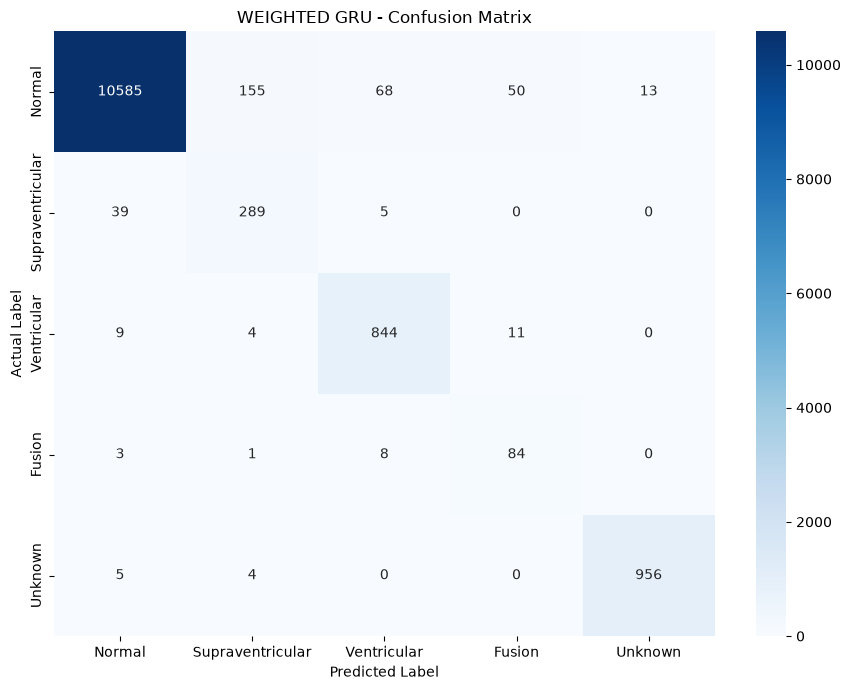

In [50]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("WEIGHTED GRU - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "../results/figures/gru_weighted_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

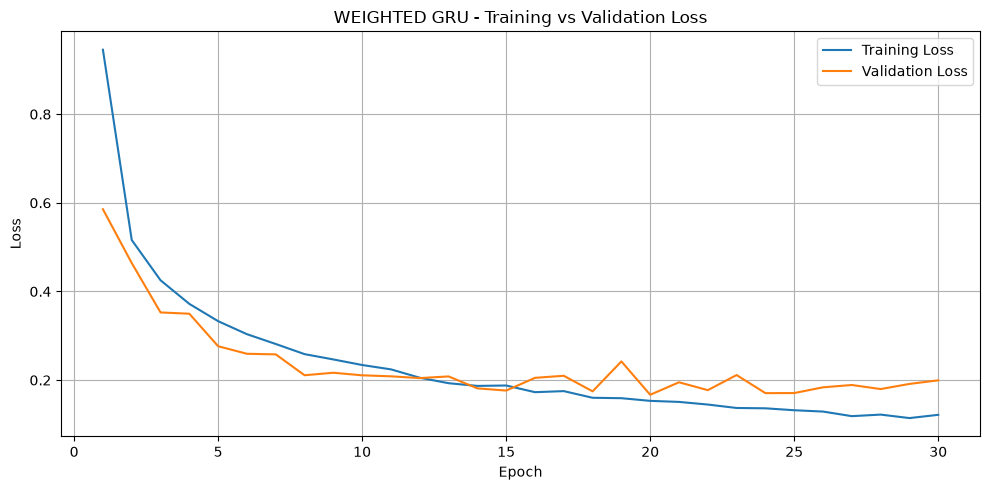

In [51]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gru_weighted["epoch"],
    history_gru_weighted["train_loss"],
    label="Training Loss"
)

plt.plot(
    history_gru_weighted["epoch"],
    history_gru_weighted["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("WEIGHTED GRU - Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/gru_weighted_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

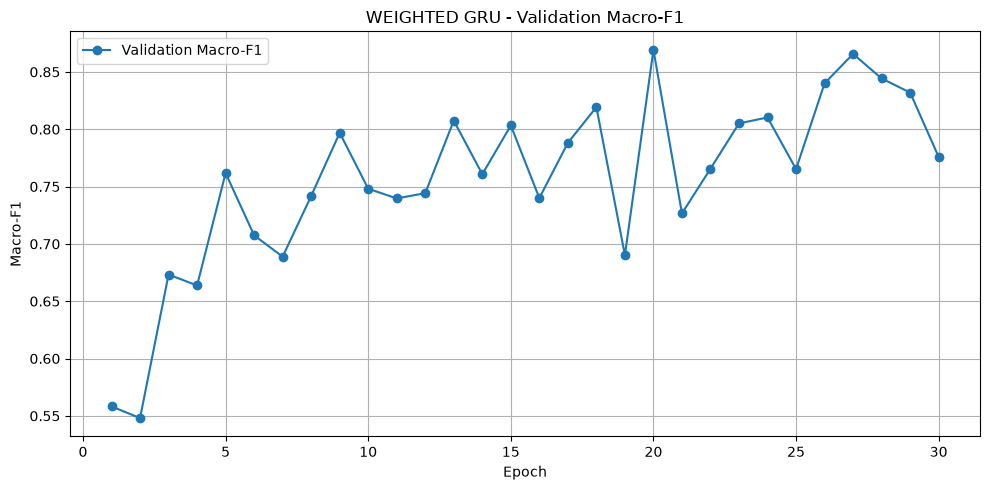

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_gru_weighted["epoch"],
    history_gru_weighted["macro_f1"],
    marker="o",
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("WEIGHTED GRU - Validation Macro-F1")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    "../results/figures/weighted_gru_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 8. Results and Comparative Analysis

The four recurrent experiments produced the following validation results:

| Model | Accuracy | Macro-F1 |
|---|---:|---:|
| LSTM Plain | 98.99% | 94.43% |
| LSTM Weighted | 97.05% | 86.60% |
| GRU Plain | 99.02% | 94.34% |
| GRU Weighted | 97.14% | 86.93% |

### Key observations

- LSTM Plain achieved the highest validation Macro-F1.
- GRU Plain achieved the highest validation accuracy and weighted F1.
- Both standard-loss recurrent models performed considerably better than their weighted counterparts in Macro-F1.
- Weighted loss improved Fusion recall for both architectures.
- However, weighted experiments generally produced lower precision and F1-scores for several classes.

The results show that the effect of class weighting varies across architectures and classes.

A higher minority-class recall does not necessarily translate into a better overall classification model.



## 9. Conclusion

The LSTM and GRU experiments demonstrate strong performance on ECG heartbeat classification.

The standard-loss versions achieved substantially higher Macro-F1 scores than their weighted counterparts.

LSTM Plain achieved the highest validation Macro-F1 of approximately 94.43%, while GRU Plain achieved the highest validation accuracy of approximately 99.02%.

Based on validation Macro-F1, LSTM Plain was provisionally selected for final evaluation on the untouched Kaggle test dataset.

The final test evaluation is documented separately in `final_test_evaluation.ipynb`.
